## Assignment 1

In [3]:
%pip install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import json
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

In [5]:
tsn = "200101723"
d = int(tsn[-2:])
s = int(tsn[-3])

x_start = (-1)**s * (0.5 + d / 200)
print(f"x_start = {x_start}")

x_start = -0.615


In [6]:
m = 1.0
omega = 1.0
hbar = 1.0
alpha = 2.0

T_0 = 2.0 * np.pi
NT = 128
ND = 600
x = np.linspace(-4.0, 4.0, ND + 1)
t = np.linspace(0, T_0, NT + 1)
dx = x[1] - x[0]
dt = T_0 / NT

In [7]:
psi0 = (
    (alpha / np.pi) ** 0.25 * np.exp(-0.5 * alpha * (x - x_start)**2)
    ).astype(complex)

### Problem A:

In [8]:
x_b = x[:, None]
x_a = x[None, :]

sinwt = np.sin(omega * dt)
coswt = np.cos(omega * dt)
K_eps = (
    np.sqrt(m * omega / (2.0 * np.pi * 1j * hbar * sinwt)) * 
    np.exp(1j * m * omega / (2.0 * hbar * sinwt) *
           ((x_a**2 + x_b**2) * coswt - 2.0 * x_a * x_b))
)

U = dx * K_eps
K_8eps = np.linalg.matrix_power(U, 8) / dx

print(f"K_8eps shape: {K_8eps.shape}")
print("\nTruncated matrix:")
print(K_8eps)

K_8eps shape: (601, 601)

Truncated matrix:
[[-0.05955846+0.0178667j  -0.0757611 +0.0217024j  -0.07967385+0.05414053j
  ... -0.46505982-0.30932634j -0.35439299-0.42735575j
  -0.21687407-0.50917202j]
 [-0.0757611 +0.0217024j  -0.0896081 +0.03330227j -0.08308486+0.06724787j
  ... -0.53404108-0.16837676j -0.46141968-0.31131639j
  -0.35439299-0.42735575j]
 [-0.07967385+0.05414053j -0.08308486+0.06724787j -0.06226964+0.09303051j
  ... -0.56407376-0.01040964j -0.53404108-0.16837676j
  -0.46505982-0.30932634j]
 ...
 [-0.46505982-0.30932634j -0.53404108-0.16837676j -0.56407376-0.01040964j
  ... -0.06226964+0.09303051j -0.08308486+0.06724787j
  -0.07967385+0.05414053j]
 [-0.35439299-0.42735575j -0.46141968-0.31131639j -0.53404108-0.16837676j
  ... -0.08308486+0.06724787j -0.0896081 +0.03330227j
  -0.0757611 +0.0217024j ]
 [-0.21687407-0.50917202j -0.35439299-0.42735575j -0.46505982-0.30932634j
  ... -0.07967385+0.05414053j -0.0757611 +0.0217024j
  -0.05955846+0.0178667j ]]


### Problem B:

In [9]:
states = np.empty((NT + 1, ND + 1), dtype=complex)
states[0] = psi0

for n in range(NT):
    states[n + 1] = U @ states[n]

P = np.abs(states)**2
norm = dx * np.sum(P, axis=1)
x_mean = dx * np.sum(P * x_a, axis=1)
print(f"States: {states.shape}, Mean positions: {x_mean.shape}")

States: (129, 601), Mean positions: (129,)


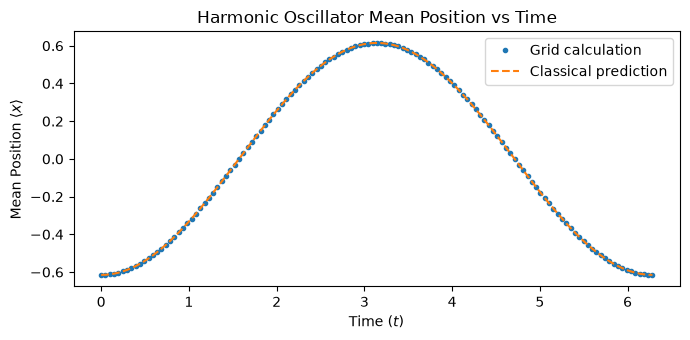

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, x_mean, "o", markersize=3, label="Grid calculation")
ax.plot(t, x_start * np.cos(omega * t), "--", label="Classical prediction")
ax.set(xlabel="Time $(t)$", ylabel="Mean Position $\\langle x \\rangle$", title="Harmonic Oscillator Mean Position vs Time")
ax.legend()
fig.tight_layout()
plt.show()

### Problem C:

In [11]:
dpsi_dx = np.gradient(states, dx, axis=1)
V_grid = 0.5 * x**2
K_mean = hbar**2 / 2.0 * dx * np.sum(np.abs(dpsi_dx)**2, axis=1)
V_mean = dx * np.sum(P * V_grid[None, :], axis=1)
E_mean = K_mean + V_mean

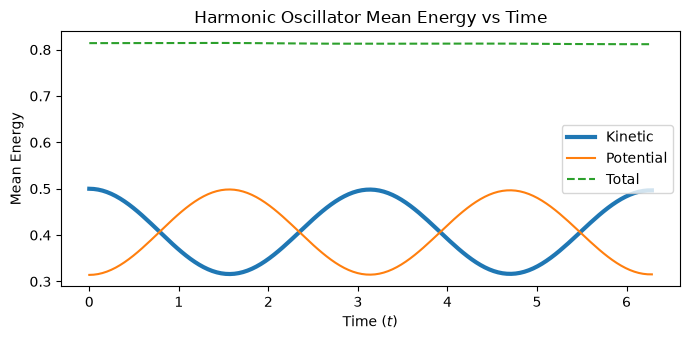

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, K_mean, label="Kinetic", linewidth=3)
ax.plot(t, V_mean, label="Potential")
ax.plot(t, E_mean, "--", label="Total")
ax.set(xlabel="Time $(t)$", ylabel="Mean Energy", title="Harmonic Oscillator Mean Energy vs Time")
ax.legend()
fig.tight_layout()
plt.show()

### Problem D

In [14]:
snapshot_indices = 8 * np.arange(9)
snapshot_times = t[snapshot_indices]
P_snapshots = P[snapshot_indices]
print("Indices:", snapshot_indices)
print("Times:", snapshot_times)
print("Density snapshots:", P_snapshots.shape)

Indices: [ 0  8 16 24 32 40 48 56 64]
Times: [0.         0.39269908 0.78539816 1.17809725 1.57079633 1.96349541
 2.35619449 2.74889357 3.14159265]
Density snapshots: (9, 601)


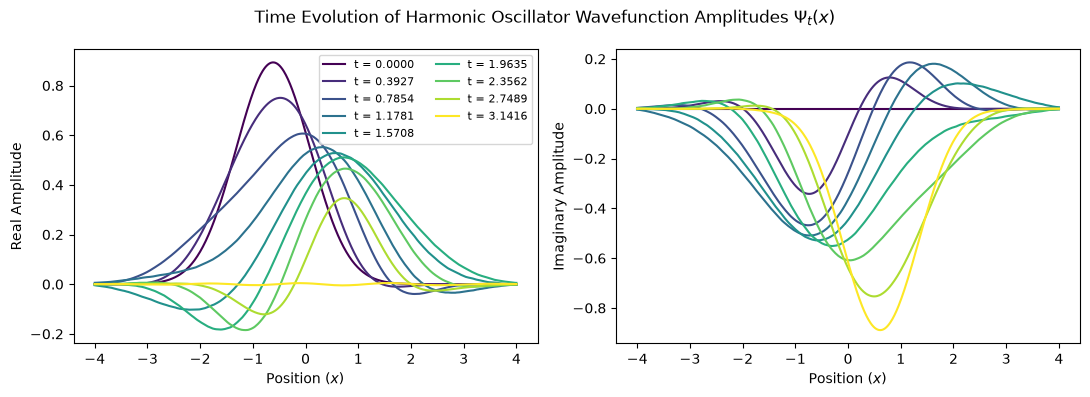

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(snapshot_indices)))
for index, color in zip(snapshot_indices, colors):
    label = f"t = {t[index]:.4f}"
    axes[0].plot(x, states[index].real, color=color, label=label)
    axes[1].plot(x, states[index].imag, color=color)
axes[0].set(xlabel="Position $(x)$", ylabel="Real Amplitude")
axes[1].set(xlabel="Position $(x)$", ylabel="Imaginary Amplitude")
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle("Time Evolution of Harmonic Oscillator Wavefunction Amplitudes $\\Psi_t(x)$")
fig.tight_layout()
plt.show()

### Problem E

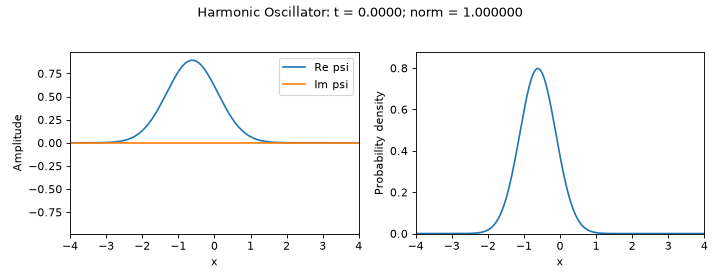

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
real_line, = axes[0].plot(x, states[0].real, label="Re psi")
imag_line, = axes[0].plot(x, states[0].imag, label="Im psi")
density_line, = axes[1].plot(x, P[0])
amplitude_limit = 1.1 * np.max(np.abs(states))
axes[0].set(xlim=(x[0], x[-1]), ylim=(-amplitude_limit, amplitude_limit),
            xlabel="x", ylabel="Amplitude")
axes[0].legend(loc="upper right")
axes[1].set(xlim=(x[0], x[-1]), ylim=(0, 1.1 * P.max()),
            xlabel="x", ylabel="Probability density")
time_label = fig.suptitle("")
fig.tight_layout(rect=(0, 0, 1, 0.9))

def update_frame(n):
    real_line.set_ydata(states[n].real)
    imag_line.set_ydata(states[n].imag)
    density_line.set_ydata(P[n])
    time_label.set_text(f"Harmonic Oscillator: t = {t[n]:.4f}; norm = {norm[n]:.6f}")
    return real_line, imag_line, density_line, time_label

animation = FuncAnimation(fig, update_frame, frames=len(t), interval=1000 / 15)
gif_path = Path("problemE.gif")
animation.save(gif_path, writer=PillowWriter(fps=15), dpi=80)
plt.close(fig)
display(Image(filename=str(gif_path)))

### Problem F

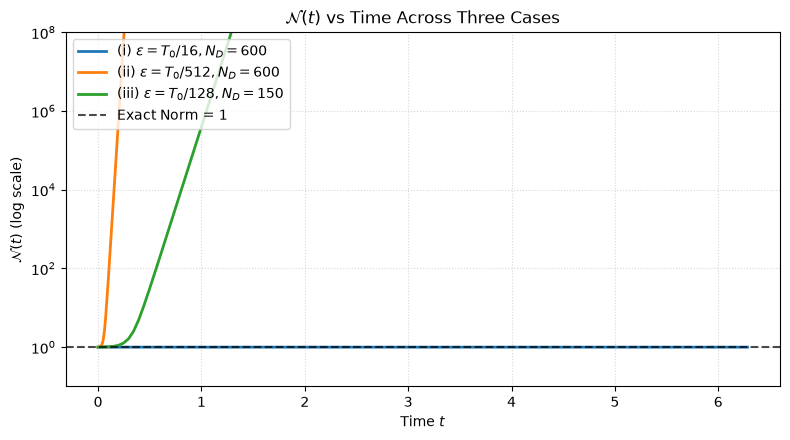

In [17]:
cases = [
    {"label": r"(i) $\epsilon = T_0/16, N_D = 600$", "NT": 16, "ND": 600},
    {"label": r"(ii) $\epsilon = T_0/512, N_D = 600$", "NT": 512, "ND": 600},
    {"label": r"(iii) $\epsilon = T_0/128, N_D = 150$", "NT": 128, "ND": 150},
]

plt.figure(figsize=(8, 4.5))

for case in cases:
    nt_case = case["NT"]
    nd_case = case["ND"]
    dt_case = T_0 / nt_case
    x_case = np.linspace(-4.0, 4.0, nd_case + 1)
    dx_case = x_case[1] - x_case[0]

    psi_curr = (
        (alpha / np.pi) ** 0.25 * np.exp(-0.5 * alpha * (x_case - x_start) ** 2)
    ).astype(complex)

    xb_case = x_case[:, None]
    xa_case = x_case[None, :]

    sinwt_case = np.sin(omega * dt_case)
    coswt_case = np.cos(omega * dt_case)

    K_case = (
        np.sqrt(m * omega / (2.0 * np.pi * 1j * hbar * sinwt_case)) *
        np.exp(1j * m * omega / (2.0 * hbar * sinwt_case) *
               ((xa_case**2 + xb_case**2) * coswt_case - 2.0 * xa_case * xb_case)
        )
    )

    U_case = dx_case * K_case
    norm_history = np.empty(nt_case + 1)
    norm_history[0] = dx_case * np.sum(np.abs(psi_curr) ** 2)

    for step in range(nt_case):
        psi_curr = U_case @ psi_curr
        norm_history[step + 1] = dx_case * np.sum(np.abs(psi_curr) ** 2)

    t_case = np.linspace(0, T_0, nt_case + 1)
    plt.semilogy(t_case, norm_history, label=case["label"], linewidth=2)

plt.axhline(1.0, color="black", linestyle="--", alpha=0.7, label="Exact Norm = 1")
plt.xlabel("Time $t$")
plt.ylabel(r"$\mathcal{N}(t)$ (log scale)")
plt.title(r"$\mathcal{N}(t)$ vs Time Across Three Cases")
plt.ylim(1e-1, 1e8)
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Results

In [ ]:
results = {
    "tsn": tsn,
    "x_start": x_start,
    "K8eps_row": {
        "re": K_8eps[300].real.tolist(),
        "im": K_8eps[300].imag.tolist()
    },
    "x_mean": x_mean.tolist(),
    "V": V_mean.tolist(),
    "K": K_mean.tolist(),
    "E": E_mean.tolist(),
    "P": P_snapshots.tolist(),
}

with open("results.json", "w") as f:
	json.dump(results, f)